# TP2 · Clasificación supervisada — Bank Marketing
**72.75 Aprendizaje Automático · 2026 Q2**

Objetivo: predecir si un cliente contratará un depósito a plazo fijo (`y = yes/no`) a partir de datos demográficos, de campañas previas y del contexto económico.

## Paso 1 · Preprocesamiento y análisis exploratorio (EDA)

Orden de trabajo (para evitar *data leakage*):
1. Carga y limpieza **sin aprender nada de los datos** (duplicados, variable con leakage).
2. **División train / test estratificada** → el test se aparta y no se mira hasta el modelo final.
3. EDA **solo sobre train**. Cada observación termina en una **decisión** para el pipeline.
4. Definición del preprocesador (escalado + codificación) dentro de un `Pipeline`, que se ajustará únicamente con datos de entrenamiento (en cada fold de la validación cruzada).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

RANDOM_STATE = 42
DATA = Path("data/bank-additional-full.csv")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

# Estilo de gráficos: colores fijos por clase (no = azul, yes = naranja), grilla discreta
C_NO, C_YES, C_GRIS = "#2a78d6", "#eb6834", "#8a8984"
PAL_Y = {"no": C_NO, "yes": C_YES}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "font.size": 10,
})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 1.1 Carga del dataset
El archivo usa `;` como separador. 41 188 llamadas, 20 variables predictoras y la variable objetivo `y`.

In [2]:
df = pd.read_csv(DATA, sep=";")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

### 1.2 Limpieza previa al split (no aprende nada de los datos)

**a) Filas duplicadas.** Si una fila duplicada cae una vez en train y otra en test, el modelo "ya vio" ese ejemplo de test → leakage. Se eliminan antes de dividir.

In [4]:
n_dup = df.duplicated().sum()
print(f"Filas duplicadas: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print("Dimensiones sin duplicados:", df.shape)

Filas duplicadas: 12
Dimensiones sin duplicados: (41176, 21)


**b) Variables con *data leakage*: `duration`.**
`duration` es la duración (en segundos) de la última llamada. Solo se conoce **después** de terminar la llamada, cuando ya se sabe el resultado; además, si `duration = 0` entonces `y = no` siempre. En la aplicación real el modelo se usaría **antes** de llamar para decidir a quién llamar, por lo que esta variable no estaría disponible.

El gráfico muestra por qué es peligrosa: separa las clases muchísimo mejor que cualquier otra variable, y un modelo entrenado con ella daría métricas infladas e irreales.

Llamadas con duration = 0 → {'no': 4}


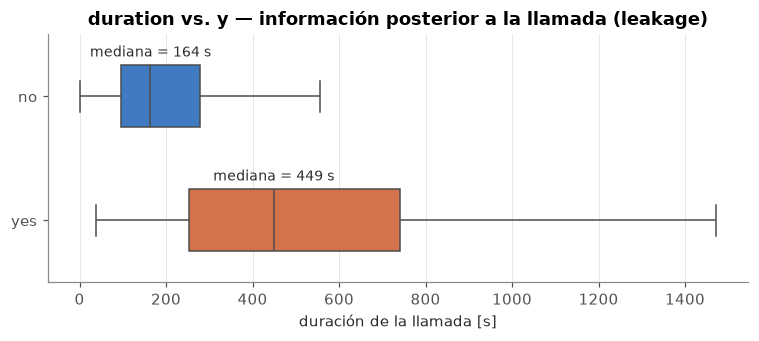

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.boxplot(data=df, x="duration", y="y", hue="y", palette=PAL_Y, showfliers=False,
            order=["no", "yes"], legend=False, ax=ax, width=0.5)
med = df.groupby("y")["duration"].median()
for i, cl in enumerate(["no", "yes"]):
    ax.text(med[cl], i - 0.32, f"mediana = {med[cl]:.0f} s", ha="center", fontsize=9, color="#2b2b2a")
print("Llamadas con duration = 0 →", df.loc[df.duration == 0, "y"].value_counts().to_dict())
ax.set(title="duration vs. y — información posterior a la llamada (leakage)", xlabel="duración de la llamada [s]", ylabel="")
guardar("01_duration_leakage")

**Decisión:** se **elimina `duration`**.

Revisión del resto de variables respecto a leakage:
- `campaign` (contactos en esta campaña, *incluyendo* el actual): se conoce al momento de llamar → se mantiene.
- `pdays`, `previous`, `poutcome`: información de campañas **anteriores** → disponible antes de llamar.
- Variables macroeconómicas (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`): indicadores públicos mensuales/trimestrales → disponibles. *(Ojo: describen el momento temporal; lo retomamos en las conclusiones.)*

In [6]:
df = df.drop(columns=["duration"])
df["y"] = df["y"].map({"no": 0, "yes": 1})
print("Dimensiones:", df.shape)

Dimensiones: (41176, 20)


### 1.3 División train / test (antes de cualquier transformación aprendida)
- **80 % train / 20 % test**, **estratificado por `y`** para conservar la proporción de la clase minoritaria en ambos conjuntos.
- El **test no se usa** hasta el Paso 4 (modelo final). Toda la exploración, la validación cruzada y el ajuste de hiperparámetros se hacen **solo con train**.
- El EDA también se hace solo sobre train: así ninguna decisión de preprocesamiento está influida por los datos de test.

In [7]:
X = df.drop(columns="y")
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  |  % yes = {y_train.mean():.2%}")
print(f"Test : {X_test.shape}  |  % yes = {y_test.mean():.2%}")

# DataFrame de train con la etiqueta, solo para el EDA
train = X_train.assign(y=y_train.values)
train["y_txt"] = train["y"].map({0: "no", 1: "yes"})

Train: (32940, 19)  |  % yes = 11.27%
Test : (8236, 19)  |  % yes = 11.27%


### 1.4 Balance de clases

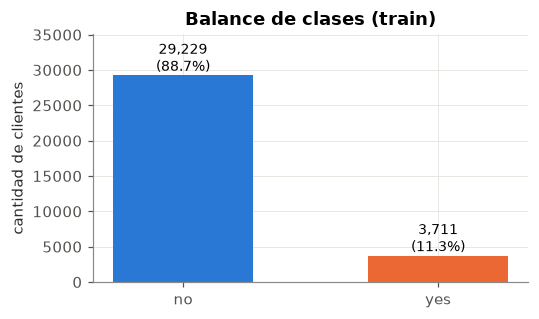

In [8]:
cnt = train["y_txt"].value_counts().reindex(["no", "yes"])
pct = cnt / cnt.sum()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(cnt.index, cnt.values, color=[C_NO, C_YES], width=0.55)
for b, n, p in zip(bars, cnt.values, pct.values):
    ax.text(b.get_x() + b.get_width()/2, n, f"{n:,}\n({p:.1%})", ha="center", va="bottom", fontsize=9)
ax.set(title="Balance de clases (train)", ylabel="cantidad de clientes", ylim=(0, cnt.max()*1.2))
guardar("02_balance_clases")

**Observación:** el dataset está **muy desbalanceado** (~88.7 % `no` vs ~11.3 % `yes`).

**Decisiones:**
- **Accuracy no sirve como métrica principal**: un clasificador que siempre diga "no" obtiene ~88.7 % sin detectar ningún cliente interesado. Se elegirán métricas que miren la clase positiva (se justifican en el Paso 2).
- Split y validación cruzada **estratificados** (`StratifiedKFold`).
- En KNN, un `k` grande tenderá a favorecer a la clase mayoritaria (visto en clase 9) → tenerlo en cuenta al elegir `k`.

### 1.5 Valores faltantes y categorías poco frecuentes
No hay `NaN`, pero los faltantes vienen codificados como la categoría `"unknown"`.

NaN en train: 0


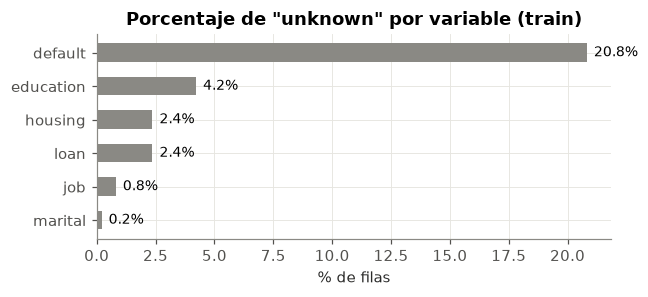

In [9]:
cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()
print("NaN en train:", int(X_train.isna().sum().sum()))

unk = (X_train[cat_cols] == "unknown").mean().sort_values()
unk = unk[unk > 0]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(unk.index, unk.values * 100, color=C_GRIS, height=0.55)
for i, v in enumerate(unk.values):
    ax.text(v*100 + 0.3, i, f"{v:.1%}", va="center", fontsize=9)
ax.set(title='Porcentaje de "unknown" por variable (train)', xlabel="% de filas")
guardar("03_unknown")

¿El `"unknown"` aporta información? Comparamos la **tasa de `yes`** de cada categoría contra la tasa global, y vemos las categorías con muy pocas observaciones.

In [10]:
tasa_global = train["y"].mean()
def tabla_cat(col):
    t = train.groupby(col)["y"].agg(n="size", tasa_yes="mean")
    t["% filas"] = t["n"] / len(train)
    return t.sort_values("n", ascending=False)

for c in ["default", "housing", "loan", "marital", "education"]:
    t = tabla_cat(c)
    t["tasa_yes"] = (t["tasa_yes"] * 100).round(1).astype(str) + " %"
    t["% filas"] = (t["% filas"] * 100).round(1).astype(str) + " %"
    print(f"--- {c} ---"); print(t.to_string(), "\n")

--- default ---
             n tasa_yes % filas
default                        
no       26081   12.8 %  79.2 %
unknown   6857    5.3 %  20.8 %
yes          2    0.0 %   0.0 % 

--- housing ---
             n tasa_yes % filas
housing                        
yes      17278   11.5 %  52.5 %
no       14883   11.0 %  45.2 %
unknown    779   11.7 %   2.4 % 

--- loan ---
             n tasa_yes % filas
loan                           
no       27157   11.3 %  82.4 %
yes       5004   11.2 %  15.2 %
unknown    779   11.7 %   2.4 % 

--- marital ---
              n tasa_yes % filas
marital                         
married   19915   10.2 %  60.5 %
single     9257   13.9 %  28.1 %
divorced   3700   10.1 %  11.2 %
unknown      68   16.2 %   0.2 % 

--- education ---
                        n tasa_yes % filas
education                                 
university.degree    9721   13.6 %  29.5 %
high.school          7605   10.9 %  23.1 %
basic.9y             4831    7.7 %  14.7 %
professional.course 

**Observaciones:**
- `default`: casi 21 % `unknown` y solo **2** clientes con `yes` → en la práctica es binaria (`no` / `unknown`). El `unknown` **sí es informativo**: su tasa de `yes` (~5 %) es menos de la mitad que la de `no` (~13 %).
- `housing` y `loan`: los `unknown` son **las mismas filas** en ambas variables (2.4 %), y la tasa de `yes` es prácticamente igual en todas sus categorías (~11 %).
- Categorías muy raras: `education = illiterate` (18 filas), `default = yes` (2), `marital = unknown` (68).

**Decisiones:**
- **No se imputa ni se eliminan filas**: `"unknown"` se trata como **una categoría más**, porque en `default` y `education` tiene una tasa de `yes` distinta (borrar esas filas tiraría información y ~25 % de los datos).
- **Categorías con menos de 100 observaciones en train** se agrupan en una categoría "infrecuente" dentro del One-Hot (`min_frequency=100`). Así se evitan columnas casi vacías que no generalizan (y probabilidades mal estimadas en Naive Bayes). Esta agrupación se aprende **dentro del pipeline**, solo con train.

### 1.6 Variables categóricas vs. variable objetivo
Tasa de `yes` por categoría. La línea punteada es la tasa global; las barras lejos de ella indican variables **discriminantes**.

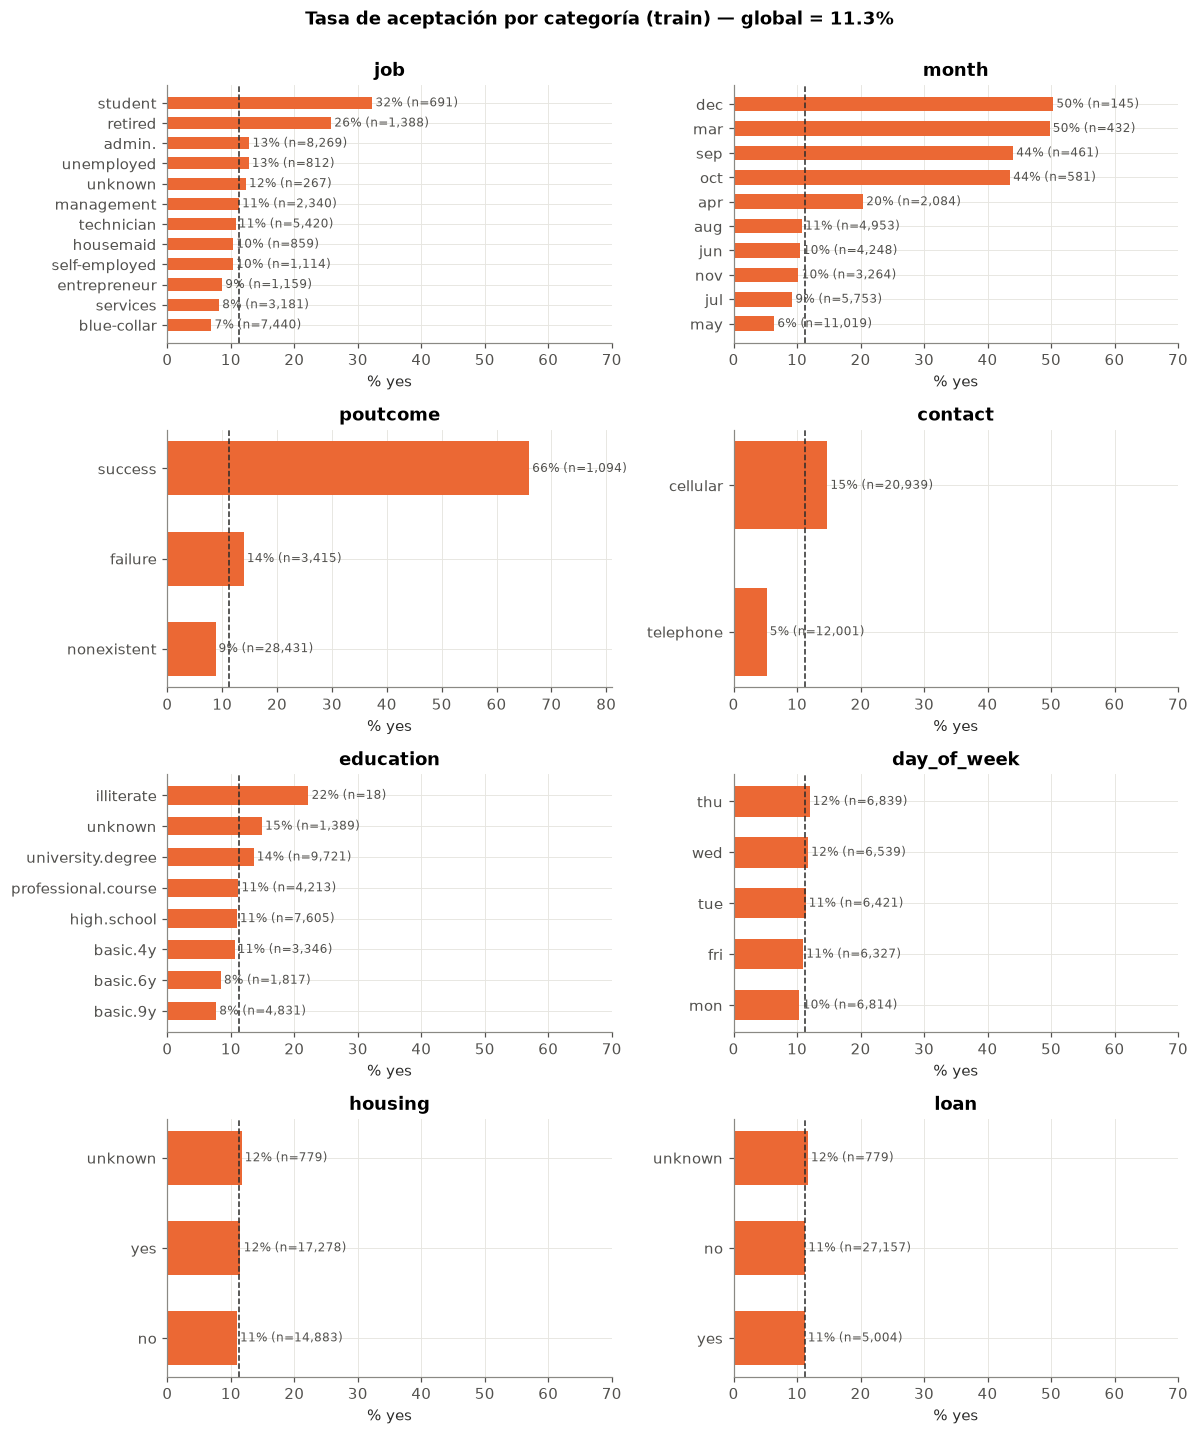

In [11]:
cols_plot = ["job", "month", "poutcome", "contact", "education", "day_of_week", "housing", "loan"]
fig, axes = plt.subplots(4, 2, figsize=(11, 13))
for ax, c in zip(axes.ravel(), cols_plot):
    t = tabla_cat(c).sort_values("tasa_yes")
    ax.barh(t.index.astype(str), t["tasa_yes"]*100, color=C_YES, height=0.6)
    ax.axvline(tasa_global*100, ls="--", color="#2b2b2a", lw=1)
    for i, (v, n) in enumerate(zip(t["tasa_yes"], t["n"])):
        ax.text(v*100 + 0.5, i, f"{v:.0%} (n={n:,})", va="center", fontsize=8, color="#52514e")
    ax.set(title=c, xlabel="% yes", xlim=(0, max(70, t['tasa_yes'].max()*100 + 15)))
fig.suptitle(f"Tasa de aceptación por categoría (train) — global = {tasa_global:.1%}", fontweight="bold", y=1.0)
guardar("04_categoricas_vs_y")

**Observaciones:**
- **`poutcome`** es la más discriminante: si la campaña anterior fue un éxito, ~66 % acepta (vs. ~9 % si no hubo campaña previa).
- **`month`**: meses con pocas llamadas (`mar`, `sep`, `oct`, `dec`) tienen tasas de 44–50 %, mientras que `may` (el mes con más llamadas) tiene ~6 %. Relación fuerte, aunque probablemente refleja *cuándo* se hizo la campaña (contexto temporal) más que una preferencia real del cliente.
- **`contact`**: celular ~15 % vs. teléfono fijo ~5 %.
- **`job`**: `student` (~32 %) y `retired` (~26 %) aceptan mucho más; `blue-collar` mucho menos (~7 %).
- **`day_of_week`, `housing` y `loan`**: todas sus categorías están en ~10–12 %, casi sobre la tasa global → **prácticamente no discriminan**.

**Decisiones:**
- **Se eliminan `housing`, `loan` y `day_of_week`**: no aportan información sobre `y` y sólo agregan dimensiones (con One-Hot serían 3 + 3 + 5 columnas). Esto perjudica especialmente a **KNN**, porque todas las features entran en la distancia aunque no sean informativas (clase 9). *(En el Paso 2 se puede verificar con CV que quitarlas no empeora los modelos.)*
- Las meses raros **no se agrupan** aunque tengan pocas filas (145–581): son justamente los más informativos y superan el umbral de 100.
- Las categóricas son **nominales** (sin orden) → **One-Hot Encoding**.

### 1.7 Variables numéricas: distribución por clase

In [12]:
print(train[num_cols].describe().T.round(2))
print("\nAsimetría (skewness):")
print(train[num_cols].skew().round(2).to_string())

                  count     mean     std      min      25%      50%      75%  \
age             32940.0    40.02   10.45    17.00    32.00    38.00    47.00   
campaign        32940.0     2.56    2.77     1.00     1.00     2.00     3.00   
pdays           32940.0   962.62  186.56     0.00   999.00   999.00   999.00   
previous        32940.0     0.17    0.50     0.00     0.00     0.00     0.00   
emp.var.rate    32940.0     0.08    1.57    -3.40    -1.80     1.10     1.40   
cons.price.idx  32940.0    93.58    0.58    92.20    93.08    93.75    93.99   
cons.conf.idx   32940.0   -40.51    4.63   -50.80   -42.70   -41.80   -36.40   
euribor3m       32940.0     3.62    1.74     0.63     1.34     4.86     4.96   
nr.employed     32940.0  5166.91   72.40  4963.60  5099.10  5191.00  5228.10   

                    max  
age               98.00  
campaign          56.00  
pdays            999.00  
previous           7.00  
emp.var.rate       1.40  
cons.price.idx    94.77  
cons.conf.idx    

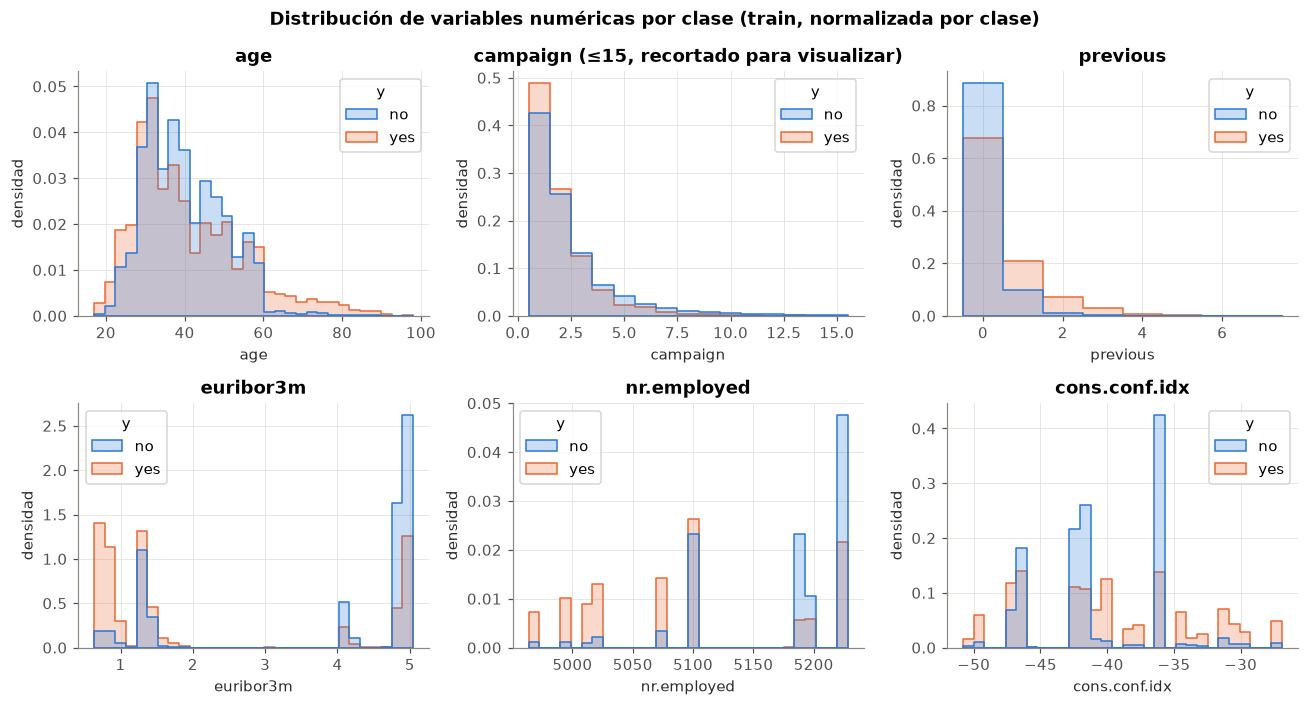

In [13]:
cols_num_plot = ["age", "campaign", "previous", "euribor3m", "nr.employed", "cons.conf.idx"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, c in zip(axes.ravel(), cols_num_plot):
    discreta = c in ["campaign", "previous"]
    data = train if c != "campaign" else train[train.campaign <= 15]
    sns.histplot(data=data, x=c, hue="y_txt", hue_order=["no", "yes"], palette=PAL_Y,
                 stat="density", common_norm=False, element="step", fill=True, alpha=0.25,
                 discrete=discreta, bins=None if discreta else 30, ax=ax)
    ax.set(title=c + (" (≤15, recortado para visualizar)" if c == "campaign" else ""), ylabel="densidad")
    ax.get_legend().set_title("y")
fig.suptitle("Distribución de variables numéricas por clase (train, normalizada por clase)", fontweight="bold")
guardar("05_numericas_por_clase")

**Observaciones:**
- **`age`**: distribuciones parecidas en el centro, pero los `yes` se concentran más en los **extremos** (menores de 25 y mayores de 60 → estudiantes y jubilados). Relación **no lineal** (correlación lineal con `y` ≈ 0.03, pero sí hay información).
- **`campaign`** y **`previous`**: muy **asimétricas** (skew ≈ 4.9 y 3.9), con colas largas (`campaign` llega a 56 llamadas). Más llamadas en la campaña actual → menor tasa de éxito.
- **Variables macro** (`euribor3m`, `nr.employed`): **bimodales**, y los `yes` se concentran en los periodos de euribor bajo y menos empleados (crisis 2008–2010). Son de las variables más discriminantes.
- Ninguna numérica luce **gaussiana** → afecta el supuesto de **Gaussian Naive Bayes**.
- **Escalas muy distintas**: `nr.employed` ~5 000, `euribor3m` ~0–5, `previous` 0–7.

**Decisiones:**
- **Estandarización (z-score)** de las numéricas: imprescindible para **KNN** y **SVM**, que usan distancias / productos internos (una variable de escala grande dominaría). Para RF no hace falta pero no lo perjudica. El escalador se ajusta **solo con train dentro del pipeline**.
- No se eliminan outliers de `campaign`: son valores reales (clientes llamados muchas veces), no errores.

### 1.8 `pdays` y el valor 999
`pdays` = días desde el último contacto de una campaña anterior; **999 significa "nunca contactado"**. No es un número real: tratarlo como 999 días haría que en el escalado y en las distancias estos clientes parezcan "muy lejanos".

In [14]:
nunca = train["pdays"] == 999
print(f"pdays = 999 en el {nunca.mean():.1%} de train")
print(train.groupby(np.where(nunca, "nunca contactado (999)", "contactado antes"))["y"]
      .agg(n="size", tasa_yes="mean").round(3))
print("\nRelación con previous / poutcome:")
print(pd.crosstab(np.where(nunca, "pdays=999", "pdays<999"), train["poutcome"]))

pdays = 999 en el 96.3% de train
                            n  tasa_yes
contactado antes         1207     0.646
nunca contactado (999)  31733     0.092

Relación con previous / poutcome:
poutcome   failure  nonexistent  success
row_0                                   
pdays<999      113            0     1094
pdays=999     3302        28431        0


**Observaciones:** el 96 % nunca fue contactado; los clientes **contactados antes** aceptan ~65 % vs. ~9 %. El valor exacto de días aporta poco frente a "sí/no fue contactado", y casi toda esa información ya está en `poutcome` y `previous`.

**Decisión (feature engineering):** se reemplaza `pdays` por una variable binaria **`contactado_antes`** (1 si `pdays != 999`). Es una regla fija fila a fila (no aprende nada de los datos), por lo que puede aplicarse a train y test sin leakage.

⚠️ **Redundancia a tener en cuenta:** de los 1 207 clientes contactados antes, 1 094 tienen `poutcome = success`. Es decir, `contactado_antes` y `poutcome_success` son casi la misma información → para Naive Bayes es evidencia contada dos veces. Lo dejamos y lo tenemos presente al interpretar NB.

### 1.8 bis · Franja etaria (nueva variable)
En 1.7 vimos que los `yes` se concentran en los **extremos** de edad, pero la correlación lineal de `age` con `y` es ≈ 0.03. Un modelo que trata `age` como una sola gaussiana (Naive Bayes) o como una pendiente lineal no puede captar esa forma de "U". Probamos agrupar en franjas:

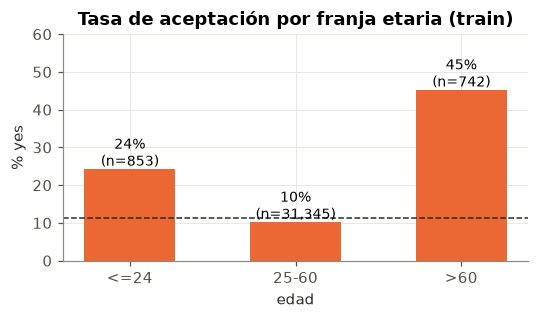

In [15]:
from tp2_comun import CORTES_EDAD, ETIQ_EDAD   # [0, 24, 60, 200] -> <=24 / 25-60 / >60
franja = pd.cut(train["age"], bins=CORTES_EDAD, labels=ETIQ_EDAD)
t = train.groupby(franja, observed=True)["y"].agg(n="size", tasa_yes="mean")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(t.index.astype(str), t["tasa_yes"]*100, color=C_YES, width=0.55)
ax.axhline(tasa_global*100, ls="--", color="#2b2b2a", lw=1)
for i, (v, n) in enumerate(zip(t["tasa_yes"], t["n"])):
    ax.text(i, v*100 + 1, f"{v:.0%}\n(n={n:,})", ha="center", fontsize=9)
ax.set(title="Tasa de aceptación por franja etaria (train)", xlabel="edad", ylabel="% yes", ylim=(0, 60))
guardar("07_franja_edad")

**Decisión:** se crea la variable categórica **`edad_grupo`** (≤24 / 25–60 / >60): 24 % / 10 % / 45 % de aceptación. Los cortes se eligieron mirando solo train y quedan **fijos**, así que es una regla fila a fila sin leakage. Como RF y KNN ya pueden captar esta forma con `age`, el beneficio esperado es sobre todo para **Naive Bayes** y **SVM lineal** → se evaluará como **variante del set B** (B con y sin `edad_grupo`) para aislar su efecto.

### 1.9 Correlación entre variables numéricas

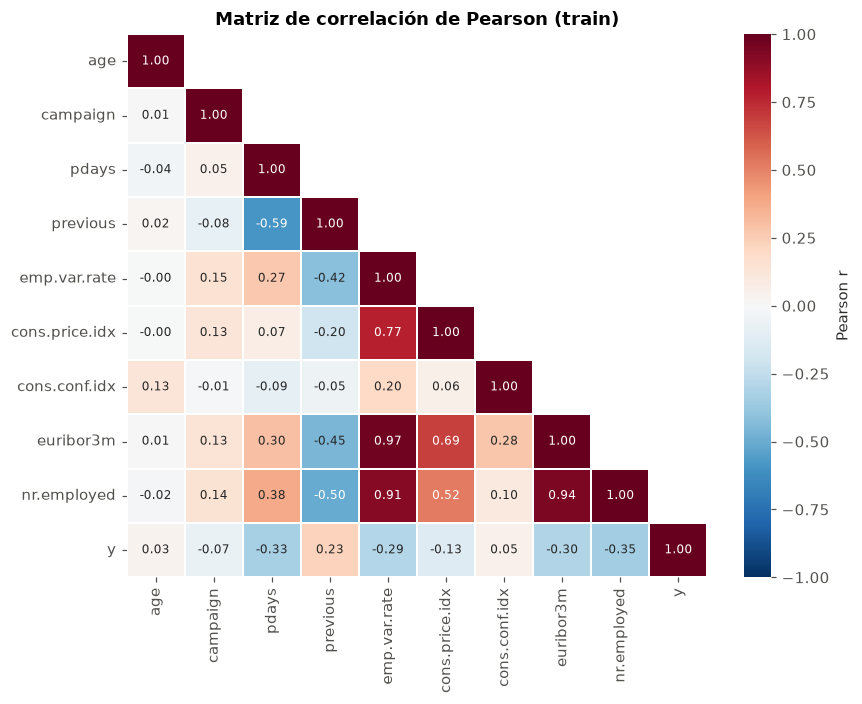

In [16]:
corr = train[num_cols + ["y"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlación de Pearson (train)")
guardar("06_correlacion")

**Observaciones:**
- `emp.var.rate`, `euribor3m` y `nr.employed` están **fuertemente correlacionadas entre sí** (r = 0.91–0.97): miden prácticamente lo mismo (el ciclo económico).
- Esto **viola la independencia condicional de Naive Bayes**: el modelo contaría tres veces la misma evidencia y sus probabilidades quedarían sobre-confiadas.
- En **KNN** también pesa: ese factor entraría triplicado en la distancia.
- De las tres, `nr.employed` es la de mayor correlación con `y` (|r| ≈ 0.35).

**Decisión:** se conserva **`nr.employed`** y se eliminan `emp.var.rate` y `euribor3m` (criterio visto en clase 7: de un grupo de variables correlacionadas, quitar todas menos una). `cons.price.idx` (r ≈ 0.69 con euribor) y `cons.conf.idx` se mantienen porque aportan información distinta.

### 1.10 Resumen de decisiones del EDA → pipeline

| Observación del EDA | Decisión |
|---|---|
| `duration` solo se conoce después de la llamada | **Eliminada** (leakage) |
| 12 filas duplicadas | Eliminadas **antes** del split |
| Clases 88.7 / 11.3 | Split y CV **estratificados**; no usar accuracy |
| `"unknown"` informativo (ej. `default`) | Se mantiene como **categoría** |
| Categorías con < 100 filas | Agrupadas como "infrecuente" en el One-Hot |
| `housing`, `loan`, `day_of_week` no discriminan | **Eliminadas** |
| `pdays = 999` = "nunca contactado" | Reemplazada por **`contactado_antes`** (binaria) |
| `age` con relación en "U" (extremos aceptan más) | Nueva variable **`edad_grupo`** (se prueba como variante) |
| `emp.var.rate`, `euribor3m`, `nr.employed` con r > 0.9 | Se conserva solo **`nr.employed`** |
| Escalas muy distintas, distribuciones no gaussianas | **StandardScaler** en numéricas (dentro del pipeline) |
| Categóricas nominales | **One-Hot Encoding** |

### 1.11 Sets de variables a comparar
El enunciado propone *"comparar el desempeño del modelo con y sin ciertas variables problemáticas"*. En lugar de confiar solo en los gráficos, las decisiones del EDA se **validarán con CV en el Paso 2** comparando tres sets (más una variante):

| Set | Variables | Pregunta que responde |
|---|---|---|
| **A · Completo** | Las 19 originales menos `duration`, sin selección ni feature engineering (`pdays` tal cual) | Línea base: ¿las decisiones del EDA mejoran o empeoran a los modelos? |
| **B · EDA** | Las 14 variables resultantes del EDA | Set principal propuesto |
| **B + edad** | B + `edad_grupo` | ¿Aporta la nueva variable? (efecto aislado) |
| **C · Sin contexto temporal** | B sin `month`, `nr.employed`, `cons.price.idx`, `cons.conf.idx` | ¿Cuánto depende el modelo de *cuándo* se llamó (contexto 2008–2010) y cuánto del *cliente*? |

Hipótesis a partir del EDA:
- A → B: deberían mejorar sobre todo **KNN** (menos dimensiones ruidosas en la distancia) y **Naive Bayes** (menos variables redundantes); **RF** debería cambiar poco porque elige sus propios cortes.
- B + edad: beneficio esperado en **Naive Bayes** / **SVM**; poco en RF / KNN.
- C: caída de desempeño; su tamaño mide la dependencia del contexto temporal (limitación para un uso en campañas futuras).

**Mismo preprocesamiento en todos los sets** (StandardScaler + One-Hot con `min_frequency=100`): así, la única diferencia entre ellos son las variables.

In [17]:
# Las reglas fijas y los sets están en tp2_comun.py para que todos los notebooks
# usen exactamente las mismas definiciones (ver ese archivo).
from tp2_comun import agregar_features, SETS, crear_preprocesador, columnas

Xtr = agregar_features(X_train)

# Chequeo (solo informativo): columnas que genera cada set al ajustar sobre train
resumen = []
for nombre in SETS:
    pre = crear_preprocesador(nombre).fit(Xtr[columnas(nombre)])
    resumen.append({"set": nombre, "variables": len(columnas(nombre)),
                    "numéricas": len(SETS[nombre]["num"]), "categóricas": len(SETS[nombre]["cat"]),
                    "columnas tras preprocesar": pre.transform(Xtr[columnas(nombre)]).shape[1]})
pd.DataFrame(resumen).set_index("set")

,variables,numéricas,categóricas,columnas tras preprocesar
set,,,,
A · Completo,19,9,10,62
B · EDA,14,7,7,49
B + edad,15,7,8,52
C · Sin contexto,10,4,6,36


**Importante:** el preprocesador se ajustó arriba solo para ver cuántas columnas genera. En los pasos siguientes se usará `crear_preprocesador(set)` dentro de un `Pipeline` junto con cada modelo, de modo que en la validación cruzada **se ajuste solo con los folds de entrenamiento**.

### 1.12 Qué datos se usan en cada etapa

| Etapa | Datos | Notebook |
|---|---|---|
| EDA y decisiones de preprocesamiento | **Train** (80 %) | `01_EDA_Preprocesamiento` |
| Comparación de modelos y de sets de variables | **Train**, con *k-fold CV estratificada*; el preprocesador se ajusta dentro de cada fold | `02_Clasificacion` |
| Curvas de validación / hiperparámetros | **Train**, con la misma CV, usando el set elegido en el Paso 2 | `03_...` |
| Estimación de performance del modelo final | **Test** (20 %), usado **una sola vez** | `04_...` |

### 1.13 Guardado de la partición
Se guardan train y test (ya sin duplicados ni `duration`, **sin ninguna transformación aprendida**) para que los siguientes notebooks usen exactamente la misma partición.

In [18]:
X_train.assign(y=y_train.values).to_csv(DATA.parent / "train.csv", index=False)
X_test.assign(y=y_test.values).to_csv(DATA.parent / "test.csv", index=False)
print("Guardados: data/train.csv", X_train.shape, "| data/test.csv", X_test.shape)

Guardados: data/train.csv (32940, 19) | data/test.csv (8236, 19)
